In [ ]:
! pip install pandas
! pip install h5py
! pip install rich
! pip install matplotlib
! pip install ipywidgets
! pip install plotly
! pip install ipympl
! pip install tqdm

In [ ]:
!

In [1]:
# Read an HDF5 dataset
import numpy as np 
import pandas as pd
import h5py
from rich.console import Console
from rich.tree import Tree
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from IPython.display import HTML, display, clear_output
import ipywidgets as widgets
from tqdm.notebook import tqdm

In [2]:
# create a console object for rich output
console = Console()

# Function to display the contents of an HDF5 file
display(HTML('''
<style>
.output_scroll {
    display: block;
    max-height: 300px;
    max-width: 100%;
    overflow: auto;
}
</style>
'''))

# visualize file structure

In [3]:
def build_tree(group, tree, max_groups=3):
    """
    Recursively build a tree structure from the HDF5 group.
    parameters:
    -----------
        group : h5py.Group
            The HDF5 group to build the tree from.
        tree : rich.tree.Tree
            The tree structure to populate.
        max_groups : int, optional
            The maximum number of groups to display.
    """
    group_count = 0
    for key in group.keys():
        branch = tree.add(f"{key}")
        item = group[key]
        if isinstance(item, h5py.Group):
            if group.name == '/':
                group_count += 1
                if group_count > max_groups:
                    tree.add("...")
                    break
            build_tree(item, branch, max_groups)
        elif isinstance(item, h5py.Dataset):
            dtype = item.dtype
            shape = item.shape
            tree.add(f"[green]{key}[/] [dim](dtype={dtype}, shape={shape})[/]")
        


In [15]:
# Display the tree structure of the HDF5 file
my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/evaluation/target0/model0/hdf5/top_20-eMBD-m0-t0-extra_properties.hdf5'
dataset_name = 'qm7x-aqm-gas-noP'
# printing the tree structure of the HDF5 file, limited to 3 groups for readability
with h5py.File(my_datset, 'r') as f:
    tree = Tree(dataset_name)
    build_tree(f, tree, max_groups=3)
    console.print(tree)

# printing the keys and values for the first molecule in the firstgroup in the HDF5 file
with h5py.File(my_datset, 'r') as f:
    first_group = list(f.keys())[0]
    first_molecule = list(f[first_group].keys())[0]
    print(f"First group: {first_group}")
    print(f"First molecule: {first_molecule}")
    for key in f[first_group][first_molecule].keys():
        value = f[first_group][first_molecule][key][()]
        print(f"{key}: {value}")

qm7x-aqm-gas-noP
└── Top20-eMBD-G-active-loop-eval
    ├── mol_10
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_14
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_15
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_19
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_20
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_22
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_27
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_29
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
    │   ├── hCHG (dtype=float64, shape=(50,))
    │   ├── hRAT
    │   ├── hRAT (dtype=float64, shape=(50,))
    │   ├── pbe0FOR
    │   ├── pbe0FOR (dtype=float64, shape=(50, 3))
    │   ├── totFOR
    │   ├── totFOR (dtype=float64, shape=(50, 3))
    │   ├── vDIP
    │   └── vDIP (dtype=float64, shape=(3,))
    ├── mol_30
    │   ├── atNUM
    │   ├── atNUM (dtype=float64, shape=(50,))
    │   ├── atXYZ
    │   ├── atXYZ (dtype=int64, shape=(50, 3))
    │   ├── hCHG
   

First group: Top20-eMBD-G-active-loop-eval
First molecule: mol_10
atNUM: [1. 6. 1. 6. 1. 1. 6. 8. 6. 6. 8. 1. 1. 8. 1. 1. 6. 8. 6. 6. 1. 6. 1. 6.
 1. 7. 6. 1. 1. 1. 6. 6. 6. 1. 6. 1. 6. 6. 7. 1. 1. 6. 1. 6. 6. 6. 7. 7.
 1. 1.]
atXYZ: [[ 0  0 -6]
 [ 0 -1  0]
 [ 0 -1 -5]
 [ 0  0  4]
 [ 3 -2  8]
 [ 1 -1  0]
 [-1  1  0]
 [ 0  2 -7]
 [-1  1 -3]
 [ 0  0 -2]
 [ 0  0  2]
 [ 0 -1 -1]
 [ 1  0  1]
 [-1  0  0]
 [-2  2 -2]
 [-2  4 -6]
 [ 0  1 -1]
 [ 2 -3  6]
 [ 0  0  1]
 [ 0  0 -5]
 [-1  2  0]
 [ 0 -2  3]
 [ 0  3 -7]
 [ 0 -1  3]
 [ 0  0  3]
 [ 0  0 -2]
 [-1  2 -3]
 [ 0  1  2]
 [ 0 -1  0]
 [ 0  1 -1]
 [ 0  0  1]
 [ 2 -2  6]
 [-1  3 -5]
 [ 0 -4  5]
 [ 0 -1 -5]
 [ 0  1  0]
 [ 0 -1 -3]
 [ 1  0  5]
 [ 0  0  0]
 [ 3 -1  7]
 [ 0 -3  3]
 [ 0  1 -5]
 [ 2  0  5]
 [ 0 -2  4]
 [ 1 -2  5]
 [-1  2 -5]
 [-2  3 -4]
 [ 3 -2  7]
 [ 0 -2 -3]
 [-2  1  0]]
hCHG: [ 0.04041094 -0.08763457  0.05662555 -0.06582246  0.13666729  0.03089434
  0.0033733  -0.17873065 -0.00153899  0.08093797 -0.11242559  0.0263835
  0.04267048 -

Processing groups:   0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_1849165/1791989643.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data.values(), labels=data.keys())


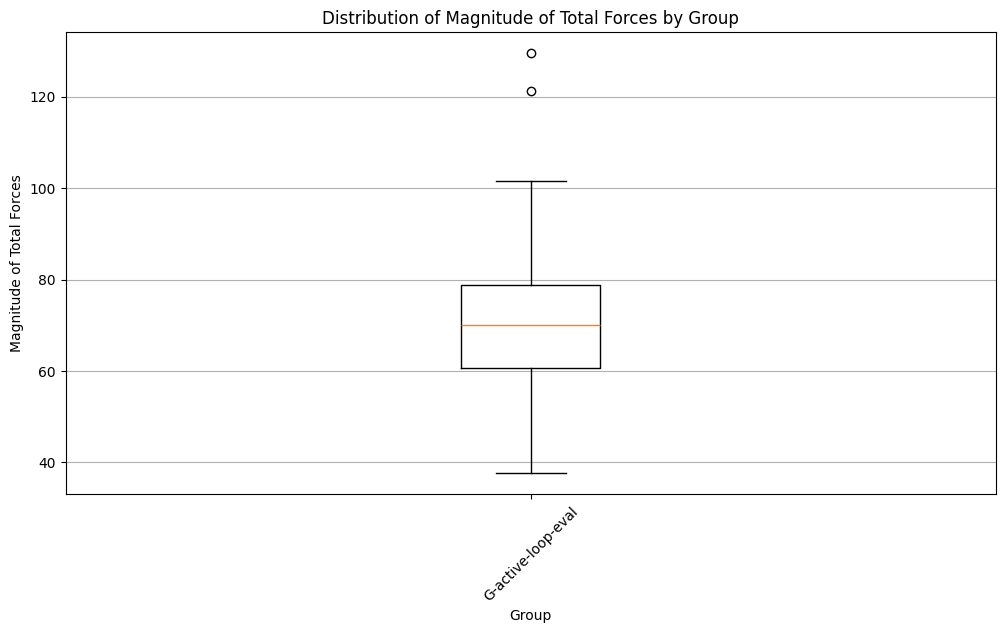

In [20]:
# printing the distribution of magnitude of sum of  x,z,y components of atom forces defined in totFOR of each molecule for molecules grouped by their group in the HDF5 file as boxplot
with h5py.File(my_datset, 'r') as f:
    group_names = list(f.keys())
    data = {}
    for group in tqdm(group_names, desc="Processing groups"):
        molecule_names = list(f[group].keys())
        forces = []
        for molecule in molecule_names:
            if 'totFOR' not in f[group][molecule]:
                print(f"Warning: 'totFOR' dataset not found for molecule '{molecule}' in group '{group}'. Skipping.")
                continue
            atomicFOR = f[group][molecule]['totFOR'][()]
            molFOR = np.sum(abs(atomicFOR), axis=0)
            net_force = np.linalg.norm(molFOR)
            forces.append(net_force)
        data[group] = forces    
# Create a boxplot of the forces for each group
plt.figure(figsize=(12, 6))
plt.boxplot(data.values(), labels=data.keys())
plt.title('Distribution of Magnitude of Total Forces by Group')
plt.xlabel('Group')
plt.ylabel('Magnitude of Total Forces')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


/tmp/ipykernel_1849165/3300325288.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


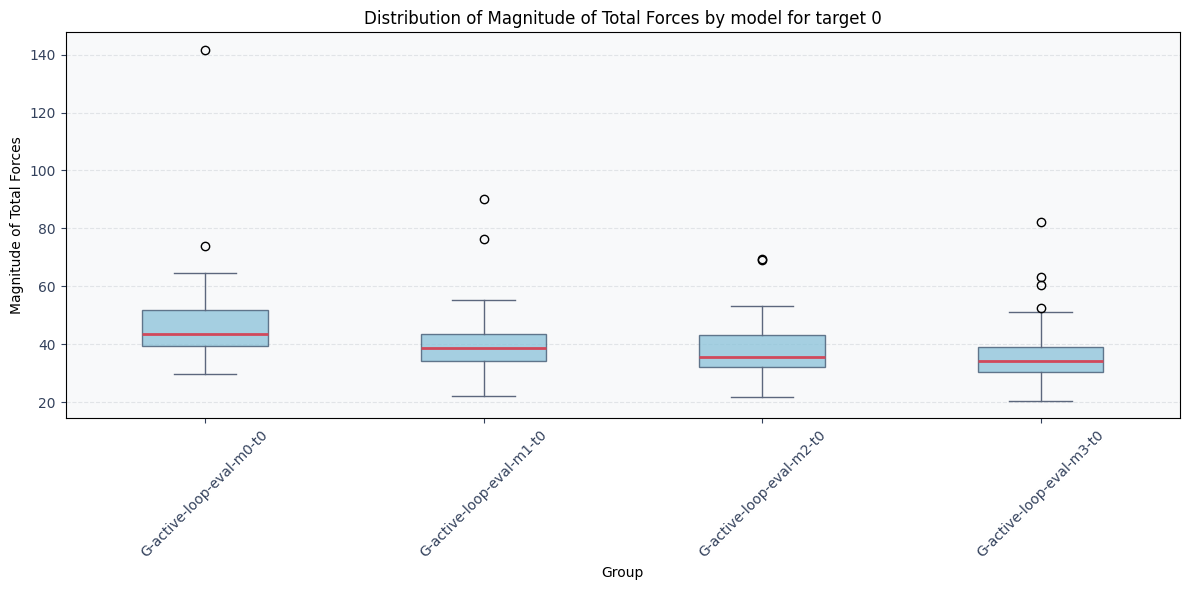

/tmp/ipykernel_1849165/3300325288.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


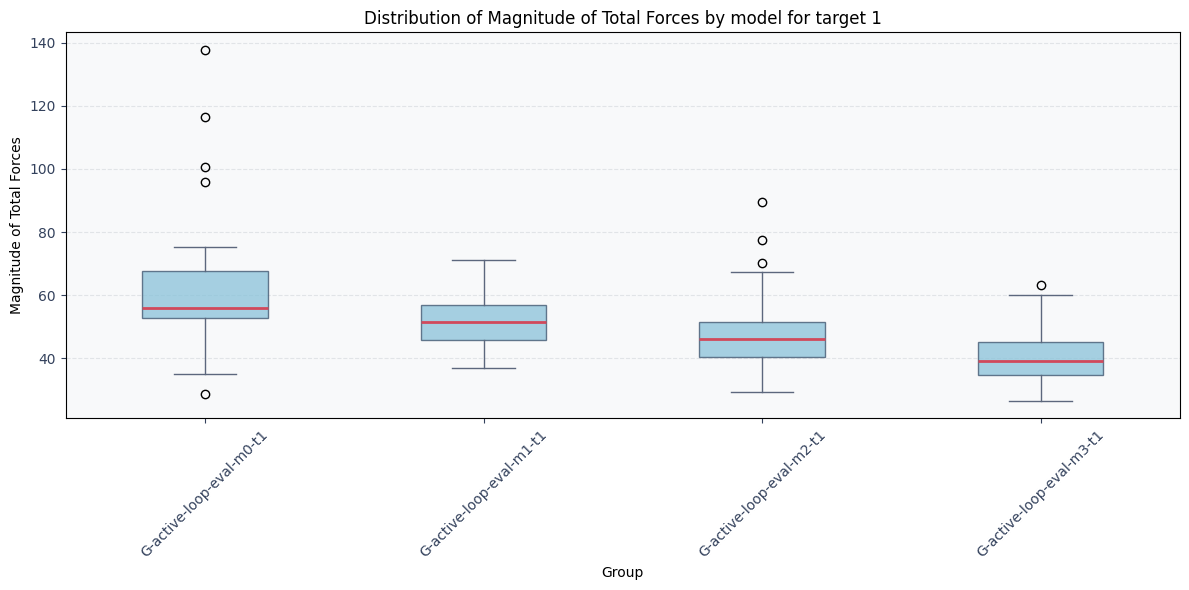

/tmp/ipykernel_1849165/3300325288.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


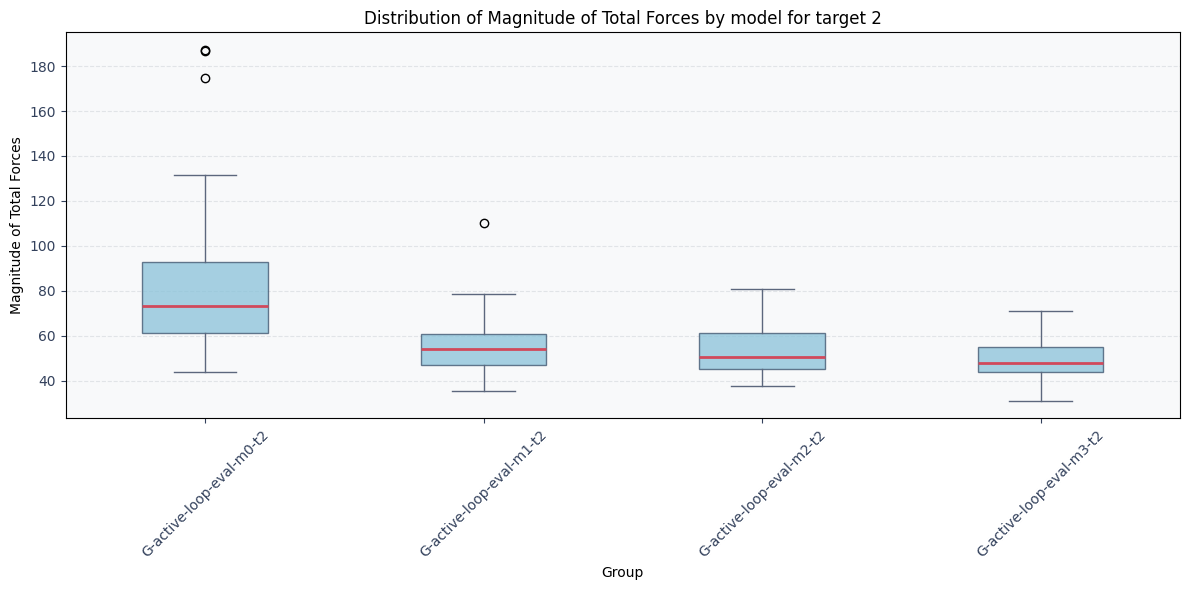

/tmp/ipykernel_1849165/3300325288.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


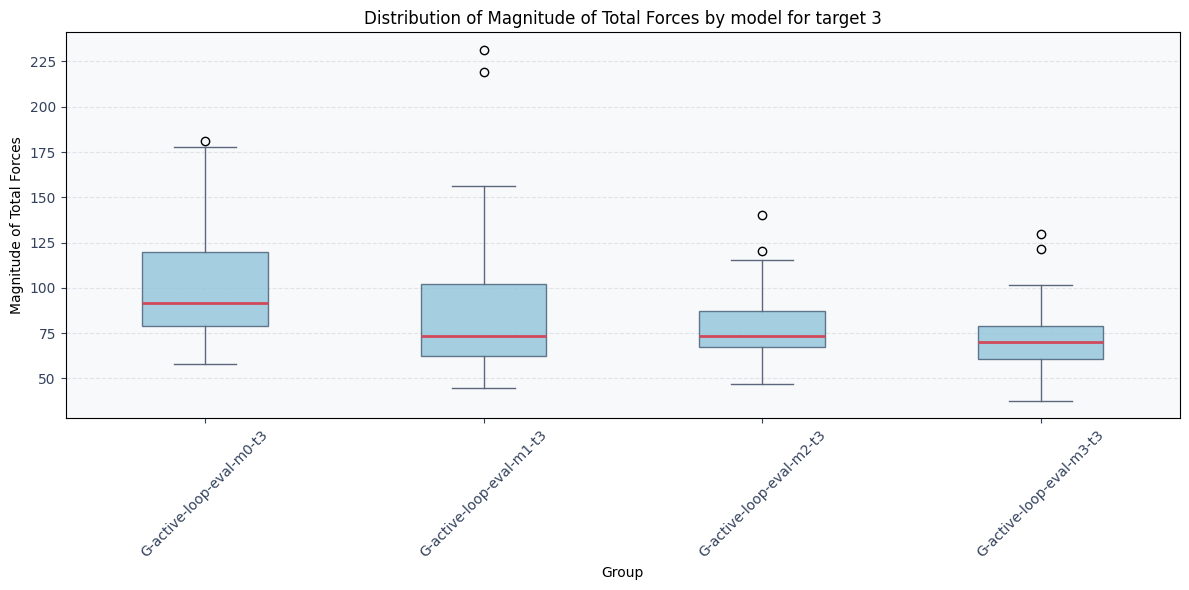

In [19]:
for t in range(4):
    data = {}
    for m in range(4):
        my_datset = f'/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/evaluation/target{t}/model{m}/hdf5/m{m}-t{t}-extra_properties.hdf5'
        dataset_name = f'm{m}-t{t}-extra_properties'
        with h5py.File(my_datset, 'r') as f:
            group_name = str(list(f.keys())[0])
            molecule_names = list(f[group_name].keys())
            forces = []
            for molecule in molecule_names:
                if 'totFOR' not in f[group_name][molecule]:
                    print(f"Warning: 'totFOR' dataset not found for molecule '{molecule}' in group '{group_name}' in model {m}'. Skipping.")
                    continue
                atomicFOR = f[group_name][molecule]['totFOR'][()]
                molFOR = np.sum(abs(atomicFOR), axis=0)
                net_force = np.linalg.norm(molFOR)
                forces.append(net_force)
        data[f'{group_name}-m{m}-t{t}'] = forces

    fig, ax = plt.subplots(figsize=(12, 6))
    bp = ax.boxplot(
        data.values(),
        labels=data.keys(),
        patch_artist=True,
        medianprops={'color': '#d1495b', 'linewidth': 2},
        whiskerprops={'color': '#5c677d'},
        capprops={'color': '#5c677d'}
    )

    for box in bp['boxes']:
        box.set_facecolor('#89c2d9')
        box.set_alpha(0.75)
        box.set_edgecolor('#3a506b')

    ax.set_title(f'Distribution of Magnitude of Total Forces by model for target {t}')
    ax.set_xlabel('Group')
    ax.set_ylabel('Magnitude of Total Forces')
    ax.tick_params(axis='x', rotation=45, colors='#33415c')
    ax.tick_params(axis='y', colors='#33415c')
    ax.grid(axis='y', linestyle='--', alpha=0.3, color='#adb5bd')
    ax.set_facecolor('#f8f9fa')
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_1849165/1598996539.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


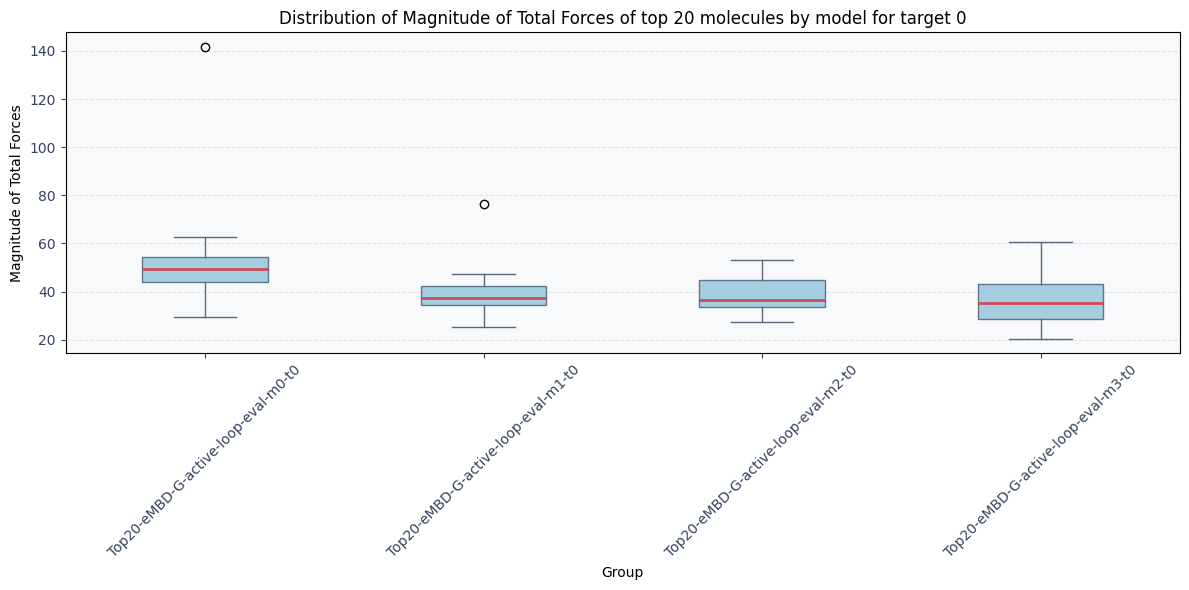

/tmp/ipykernel_1849165/1598996539.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


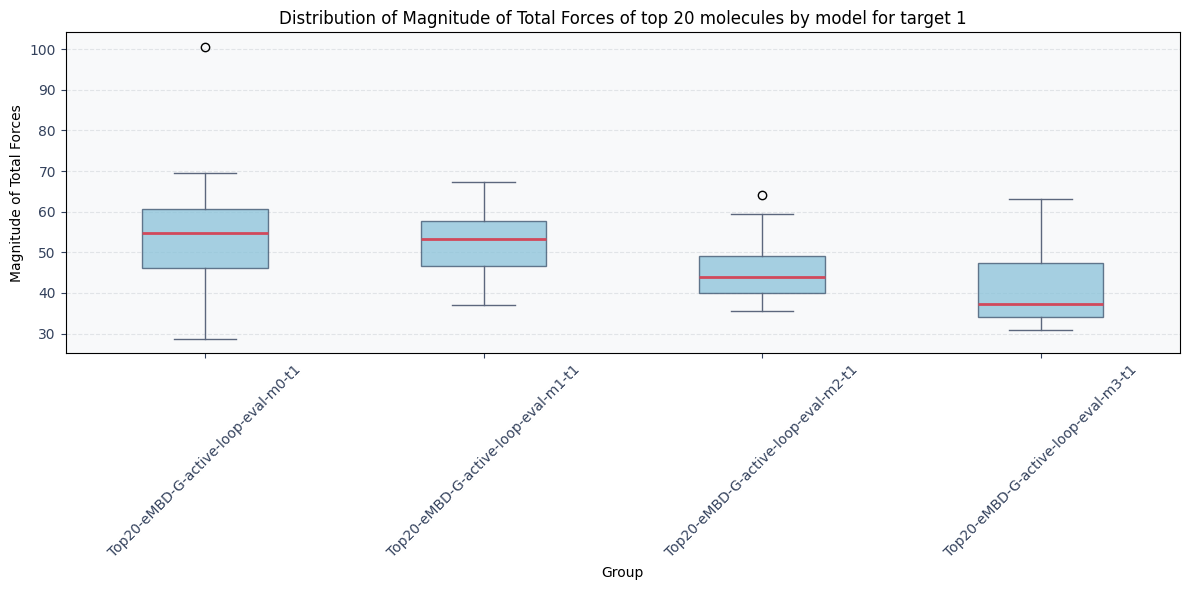

/tmp/ipykernel_1849165/1598996539.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


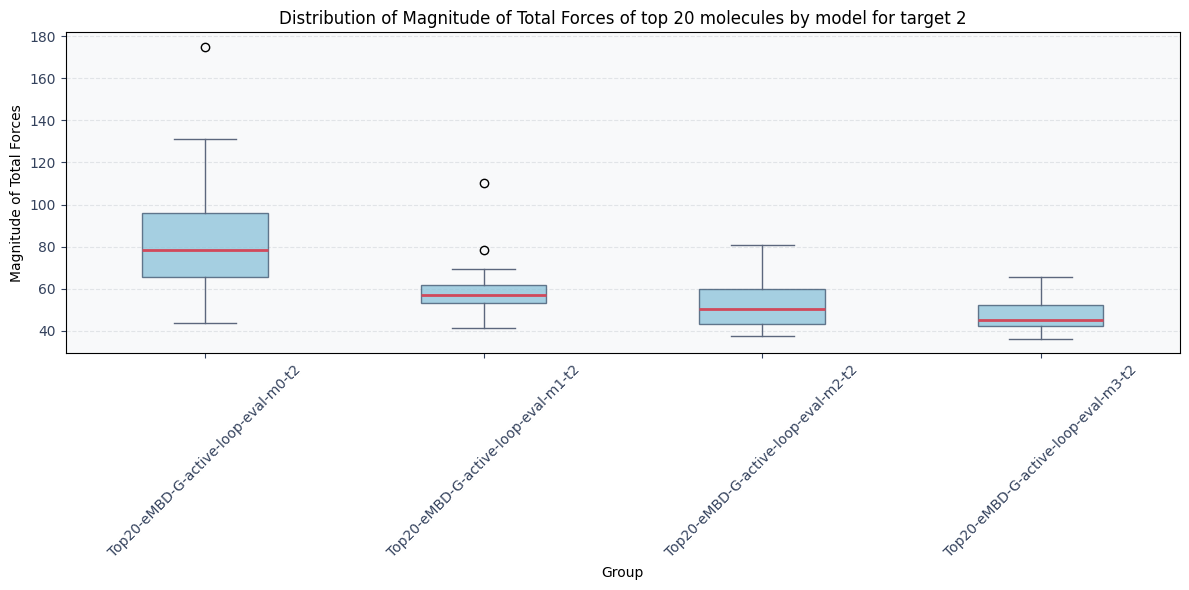

/tmp/ipykernel_1849165/1598996539.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


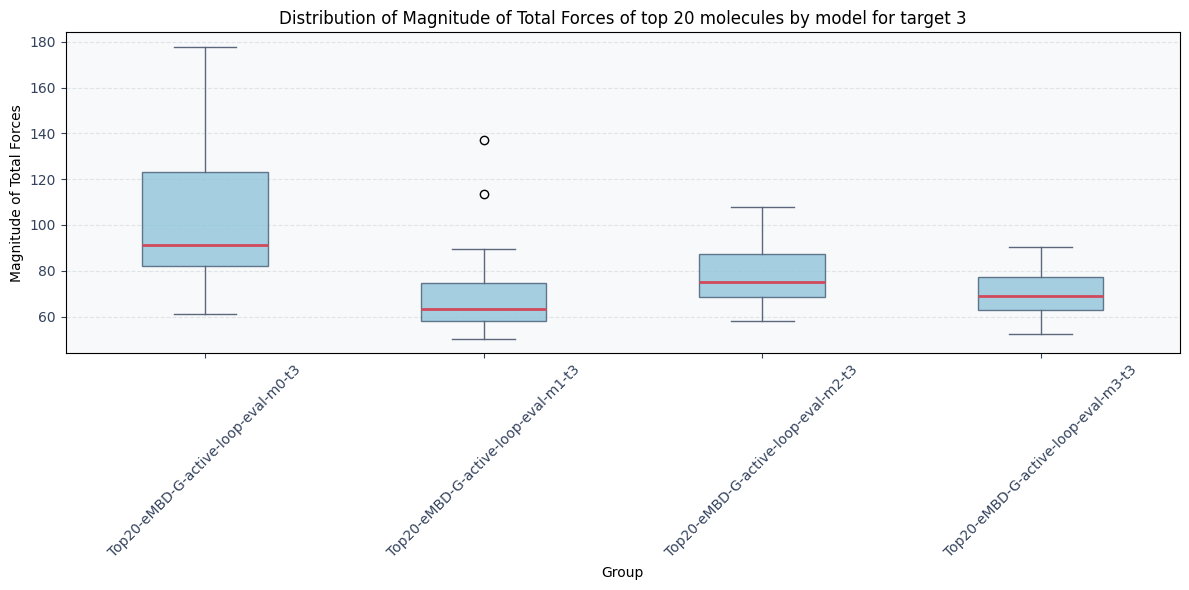

In [18]:
# print top 20 forces for each target and model in a table
prop = "eMBD"
for t in range(4):
    data = {}
    for m in range(4):
        my_datset = f'/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/evaluation/target{t}/model{m}/hdf5/top_20-{prop}-m{m}-t{t}-extra_properties.hdf5'
        dataset_name = f'm{m}-t{t}-extra_properties'
        with h5py.File(my_datset, 'r') as f:
            group_name = str(list(f.keys())[0])
            molecule_names = list(f[group_name].keys())
            forces = []
            for molecule in molecule_names:
                if 'totFOR' not in f[group_name][molecule]:
                    print(f"Warning: 'totFOR' dataset not found for molecule '{molecule}' in group '{group_name}' in model {m}'. Skipping.")
                    continue
                atomicFOR = f[group_name][molecule]['totFOR'][()]
                molFOR = np.sum(abs(atomicFOR), axis=0)
                net_force = np.linalg.norm(molFOR)
                forces.append(net_force)
        data[f'{group_name}-m{m}-t{t}'] = forces

    fig, ax = plt.subplots(figsize=(12, 6))
    bp = ax.boxplot(
        data.values(),
        labels=data.keys(),
        patch_artist=True,
        medianprops={'color': '#d1495b', 'linewidth': 2},
        whiskerprops={'color': '#5c677d'},
        capprops={'color': '#5c677d'}
    )

    for box in bp['boxes']:
        box.set_facecolor('#89c2d9')
        box.set_alpha(0.75)
        box.set_edgecolor('#3a506b')

    ax.set_title(f'Distribution of Magnitude of Total Forces of top 20 molecules by model for target {t}')
    ax.set_xlabel('Group')
    ax.set_ylabel('Magnitude of Total Forces')
    ax.tick_params(axis='x', rotation=45, colors='#33415c')
    ax.tick_params(axis='y', colors='#33415c')
    ax.grid(axis='y', linestyle='--', alpha=0.3, color='#adb5bd')
    ax.set_facecolor('#f8f9fa')
    plt.tight_layout()
    plt.show()

Check data

In [6]:
# Display the tree structure of the HDF5 file
#my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/data/hdf5/qm7x-aqm-gas-noP-input.hdf5'
#my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/datasets/iter_0/hdf5/output.hdf5'
my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/hdf5/qm7x-aqm-gas-noP-output.hdf5'
dataset_name = 'diffused-qm7x-aqm-gas-noP'
with h5py.File(my_datset, 'r') as f:
    tree = Tree(dataset_name)
    build_tree(f, tree, max_groups=3)
    console.print(tree)

NameError: name 'build_tree' is not defined

In [ ]:
my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_triangle_traj/hdf5/qm7x-aqm-gas-noP-output.hdf5'
dataset_name = 'aqm_qm7x'
# look for molecules under group G-active-loop-2
with h5py.File(my_datset, 'r') as f:
    grp = f['G-active-loop-2']
    # print the number of molecules
    print(f"Number of molecules in G-active-loop-9: {len(grp)}")
    # print name of the first all molecules in this group and order them by their IDs alphabetically
    print(f"molecule IDs: {list(grp.keys())[:]}")
    # print the first molecule
    mol_id = list(grp.keys())[0]
    print(f"First molecule ID: {mol_id}")
    tree = Tree(dataset_name)
    build_tree(grp[mol_id], tree, max_groups=3)
    console.print(tree)
    # print values of the first molecule
    for key, value in grp[mol_id].items():
        print(f"{key}: {value[()]}")
    

KeyError: "Unable to synchronously open object (object 'G-active-loop-2' doesn't exist)"

In [ ]:
my_datset = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_jmp/hdf5/molecules-fps-40000-output.hdf5'
dataset_name = 'aqm_qm7x'
# look for molecules under group G-active-loop-2
with h5py.File(my_datset, 'r') as f:
    for i in range(8):
        group_name = f'G-active-loop-{i}'
        grp = f[group_name]
        # print the number of molecules
        print(f"Number of molecules in G-active-loop-{i}: {len(grp)}")

Number of molecules in G-active-loop-0: 28
Number of molecules in G-active-loop-1: 69
Number of molecules in G-active-loop-2: 67
Number of molecules in G-active-loop-3: 136
Number of molecules in G-active-loop-4: 38
Number of molecules in G-active-loop-5: 22
Number of molecules in G-active-loop-6: 78
Number of molecules in G-active-loop-7: 77


# visualize properties

In [ ]:
#file_path = '/data/horse/ws/miha493e-research_project/activediffusion/data/qm7x-aqm-gas-noP.hdf5'
# file_path = '/data/horse/ws/miha493e-research_project/activediffusion/experiments/exp8/results/descriptors2/filtered_molecules.h5'
file_path1 = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_full_dataset/hdf5/qm7x-aqm-gas-noP-output.hdf5'
file_path2 = '/data/horse/ws/miha493e-research_project/activediffusion/data/data_embd_hlgap/hdf5/molecules-fps-40000-output.hdf5'

## one property distribution

In [ ]:
def plot_property_dist(dataset, prop='atNUM'):
    """
    Plot the distribution of a specified property (default is 'atNUM') in the dataset.
    Parameters:
    -----------
        dataset : str
            Path to the HDF5 dataset.
        prop : str, optional
            The property to plot (default is 'atNUM').
    """

    with h5py.File(dataset, 'r') as f:
        property_values = []
        for subset in f.keys():
            if isinstance(f[subset], h5py.Group):
                for molecule in f[subset].keys():
                    if prop in f[subset][molecule]:
                        if prop == 'atNUM':
                            # Append the number of atoms for each molecule
                            property_values.append(len(f[subset][molecule][prop][()]))
                        else:
                            # Append the property value for each molecule
                            property_values.append(f[subset][molecule][prop][()])
    property_values = np.array(property_values).flatten()
    plt.figure(figsize=(10, 6))
    plt.hist(property_values, bins=10, edgecolor='black', alpha=0.7)
    plt.xlabel(prop)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {prop} in Molecules')
    #plt.xticks(range(1, max(property_values) + 1))
    plt.xticks(fontsize=5)
    plt.grid(axis='y', alpha=0.75)
    plt.tight_layout()
    plt.savefig(f"/data/horse/ws/miha493e-research_project/activediffusion/results/{prop}_distribution.png", dpi=300)
    #plt.show()
    plt.close()

In [ ]:
# Dropdown for property selection
molecule_prop = [
    'DIP',
    'HLgap',
    'atNUM',
    'atXYZ',
    'eAT',
    'eC',
    'eEE',
    'eH',
    'eKIN',
    'eL',
    'eMBD',
    'eNE',
    'eNN',
    'ePBE0',
    'ePBE0+MBD',
    'eTS',
    'eX',
    'eXC',
    'eXX',
    'mC6',
    'mPOL'
]
prop1_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 1:', style={'description_width': 'initial'})
show_button = widgets.Button(description="Show Plot")
# Output area for displaying data
output1 = widgets.Output()

# Callback function for molecule selection
def on_prop1_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global x_axis
    if change['type'] == 'change' and change['name'] == 'value':
        x_axis = change['new']

   
def on_show_plot(b):
    """
    Callback function to handle the show plot button click.
    """
    global x_axis
    with output1:
        clear_output()
        plot_property_dist(file_path, prop=x_axis)

        

# Connect callbacks
prop1_dropdown.observe(on_prop1_change)
show_button.on_click(on_show_plot)


# Display widgets and output
display(widgets.VBox([widgets.HBox((prop1_dropdown, show_button)), output1]))
x_axis = prop1_dropdown.value

## Two properties distribution

In [ ]:
# update this function to show data points in groups  G-active-loop-{i} and plot them with different colors

def extract_properties2(file_path, property1, property2):
    """
    Extract arrays for two properties from the specified HDF5 file and dataset,
    tracking which G-active-loop group each point comes from.

    Parameters:
    -----------
    file_path : str
        Path to the HDF5 file.
    property1 : str
        The first property to extract (e.g., 'HLgap').
    property2 : str
        The second property to extract (e.g., 'eMBD').

    Returns:
    --------
    tuple
        Four lists: (property1_values, property2_values, group_labels, group_numbers)
    """

    property1_values = []
    property2_values = []
    group_labels = []
    group_numbers = []

    with h5py.File(file_path, "r") as f:
        for subset in f.keys():
            # Only process groups that contain 'G-active-loop' in their name
            if not isinstance(f[subset], h5py.Group) or 'G-active-loop' not in subset:
                continue
            
            # Extract group number from subset name (e.g., 'G-active-loop-2' -> 2)
            try:
                group_num = int(subset.split('-')[-1])
            except (ValueError, IndexError):
                continue
            
            for geom in f[subset].keys():
                if property1 in f[subset][geom].keys() and property2 in f[subset][geom].keys():
                    prop1 = f[subset][geom][property1][()]
                    prop2 = f[subset][geom][property2][()]

                    # Convert to scalar if numpy array with zero dims
                    if hasattr(prop1, 'shape') and prop1.shape == ():
                        prop1 = float(prop1)
                    if hasattr(prop2, 'shape') and prop2.shape == ():
                        prop2 = float(prop2)

                    property1_values.append(prop1)
                    property2_values.append(prop2)
                    group_labels.append(subset)
                    group_numbers.append(group_num)

    return property1_values, property2_values, group_labels, group_numbers

In [ ]:
def show_properties2(prop1_name, prop1_values, prop2_name, prop2_values, group_labels=None, group_numbers=None):
    """
    Display two properties with different colors for different G-active-loop groups.

    Parameters:
    -----------
    prop1_name : str
        Name of the first property.
    prop1_values : list
        List of values for the first property.
    prop2_name : str
        Name of the second property.
    prop2_values : list
        List of values for the second property.
    group_labels : list, optional
        List of group labels (e.g., 'G-active-loop-2').
    group_numbers : list, optional
        List of group numbers extracted from labels.
    """
    if prop1_name == 'atNUM':
        prop1_values = [len(v) for v in prop1_values]
    if prop2_name == 'atNUM':
        prop2_values = [len(v) for v in prop2_values]

    prop1_values = np.array(prop1_values).flatten()
    prop2_values = np.array(prop2_values).flatten()

    plt.figure(figsize=(10, 7))
    
    if group_numbers is not None and len(group_numbers) > 0:
        # Plot each group with a different color
        unique_groups = sorted(set(group_numbers))
        colors = plt.cm.tab10(np.linspace(0, 1, len(unique_groups)))
        
        for idx, group_num in enumerate(unique_groups):
            mask = np.array(group_numbers) == group_num
            plt.scatter(prop1_values[mask], prop2_values[mask], 
                       s=10, alpha=0.6, label=f'G-active-loop-{group_num}',
                       color=colors[idx])
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    else:
        # Fallback to single color if no group information
        plt.scatter(prop1_values, prop2_values, s=10, alpha=0.5)
    
    plt.xlabel(prop1_name, fontsize=12)
    plt.ylabel(prop2_name, fontsize=12)
    plt.title(f"Plot of {prop1_name} vs {prop2_name}", fontsize=14)
    plt.margins(x=0.2, y=0.2)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.xlim(2, 5)
    plt.ylim(-3, -0.5)
    plt.savefig(f"/data/horse/ws/miha493e-research_project/activediffusion/results/plot_{prop1_name}_vs_{prop2_name}_by_group.png", dpi=300)
    plt.show()

In [ ]:
def on_show_plot(b):
    """
    Callback function to handle the show plot button click.
    """
    global x_axis, y_axis
    with output2:
        clear_output()
        x_values1, y_values1, group_labels1, group_numbers1 = extract_properties2(file_path1, x_axis, y_axis)
        x_values2, y_values2, group_labels2, group_numbers2 = extract_properties2(file_path2, x_axis, y_axis)

        show_properties2(x_axis, x_values1, y_axis, y_values1, group_labels1, group_numbers1)
        show_properties2(x_axis, x_values2, y_axis, y_values2, group_labels2, group_numbers2)

In [ ]:
# Dropdown for property selection
molecule_prop = [
    'DIP',
    'HLgap',
    'atNUM',
    'atXYZ',
    'eAT',
    'eC',
    'eEE',
    'eH',
    'eKIN',
    'eL',
    'eMBD',
    'eNE',
    'eNN',
    'ePBE0',
    'ePBE0+MBD',
    'eTS',
    'eX',
    'eXC',
    'eXX',
    'mC6',
    'mPOL'
]
prop1_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 1:', style={'description_width': 'initial'})
prop2_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 2:', style={'description_width': 'initial'})
show_button = widgets.Button(description="Show Plot")
# Output area for displaying data
output2 = widgets.Output()

# Callback function for molecule selection
def on_prop1_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global x_axis
    if change['type'] == 'change' and change['name'] == 'value':
        x_axis = change['new']

def on_prop2_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global y_axis
    if change['type'] == 'change' and change['name'] == 'value':
        y_axis = change['new']

# Connect callbacks
prop1_dropdown.observe(on_prop1_change)
prop2_dropdown.observe(on_prop2_change)
show_button.on_click(on_show_plot)

# Display widgets and output
display(widgets.VBox([prop1_dropdown, widgets.HBox((prop2_dropdown, show_button)), output2]))
x_axis = prop1_dropdown.value
y_axis = prop2_dropdown.value

In [ ]:
# Dropdown for property selection
molecule_prop = [
    'DIP',
    'HLgap',
    'atNUM',
    'atXYZ',
    'eAT',
    'eC',
    'eEE',
    'eH',
    'eKIN',
    'eL',
    'eMBD',
    'eNE',
    'eNN',
    'ePBE0',
    'ePBE0+MBD',
    'eTS',
    'eX',
    'eXC',
    'eXX',
    'mC6',
    'mPOL'
]
prop1_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 1:', style={'description_width': 'initial'})
prop2_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 2:', style={'description_width': 'initial'})
prop3_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 3:', style={'description_width': 'initial'})
show_button = widgets.Button(description="Show Plot")

# Output area for displaying data
output3 = widgets.Output()

# Callback function for molecule selection
def on_prop1_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global x_axis
    if change['type'] == 'change' and change['name'] == 'value':
        x_axis = change['new']

def on_prop2_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global y_axis
    if change['type'] == 'change' and change['name'] == 'value':
        y_axis = change['new']

def on_prop3_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global z_axis
    if change['type'] == 'change' and change['name'] == 'value':
        z_axis = change['new']

def on_show_plot(b):
    """
    Callback function to handle the show plot button click.
    """
    global x_axis, y_axis, z_axis
    with output3:
        clear_output()
        x_values, y_values, z_values = extract_properties3(file_path, x_axis, y_axis, z_axis)
        show_properties3(x_axis, x_values, y_axis, y_values, z_axis, z_values)

        

# Connect callbacks
prop1_dropdown.observe(on_prop1_change)
prop2_dropdown.observe(on_prop2_change)
prop3_dropdown.observe(on_prop3_change)
show_button.on_click(on_show_plot)


# Display widgets and output
display(widgets.VBox([prop1_dropdown, widgets.HBox((prop2_dropdown, show_button)), prop3_dropdown, output3]))
x_axis = prop1_dropdown.value
y_axis = prop2_dropdown.value
z_axis = prop3_dropdown.value

## Three properties distribution

In [ ]:
def extract_properties3(file_path, property1, property2, property3):
    """
    Extract arrays for 'HLgap' and 'eMBD' from the specified HDF5 file and dataset.

    Parameters:
    -----------
    file_path : str
        Path to the HDF5 file.
    property1 : str
        The first property to extract (e.g., 'HLgap').
    property2 : str
        The second property to extract (e.g., 'eMBD').
    property3 : str
        The third property to extract (e.g., 'atNUM').

    Returns:
    --------
    tuple
        Two lists containing the extracted values for the specified properties.
    """

    property1_values = []
    property2_values = []
    property3_values = []

    with h5py.File(file_path, "r") as f:
        for subset in f.keys():
            if isinstance(f[subset], h5py.Group):
                for geom in f[subset].keys():
                    if property1 in f[subset][geom].keys() and property2 in f[subset][geom].keys() and property3 in f[subset][geom].keys():
                        prop1 = f[subset][geom][property1][()]
                        prop2 = f[subset][geom][property2][()]
                        prop3 = f[subset][geom][property3][()]

                        # Convert to scalar if numpy array with zero dims
                        if hasattr(prop1, 'shape') and prop1.shape == ():
                            prop1 = float(prop1)
                        if hasattr(prop2, 'shape') and prop2.shape == ():
                            prop2 = float(prop2)
                        if hasattr(prop3, 'shape') and prop3.shape == ():
                            prop3 = float(prop3)

                        property1_values.append(prop1)
                        property2_values.append(prop2)
                        property3_values.append(prop3)

    return property1_values, property2_values, property3_values

In [ ]:
def show_properties3(prop1_name, prop1_values, prop2_name, prop2_values, prop3_name, prop3_values):
    """
    Display the first 10 values of two properties.

    Parameters:
    -----------
    prop1_values : list
        List of values for the first property.
    prop2_values : list
        List of values for the second property.
    prop3_values : list
        List of values for the third property.
    -----------
    """
    # cleaned_prop3_values = [
    #     val[0] if isinstance(val, (list, np.ndarray)) else val
    #     for val in prop3_values
    # ]

    if prop1_name == 'atNUM':
        prop1_values = [len(v) for v in prop1_values]
    if prop2_name == 'atNUM':
        prop2_values = [len(v) for v in prop2_values]
    if prop3_name == 'atNUM':
        prop3_values = [len(v) for v in prop3_values]
    prop1_values = np.array(prop1_values).flatten()
    prop2_values = np.array(prop2_values).flatten()
    prop3_values = np.array(prop3_values).flatten()

    plt.figure(figsize=(8,6))
    plt.hexbin(
        prop1_values,
        prop2_values,
        C=prop3_values,
        gridsize=100,
        alpha=1,
        mincnt=1,
        reduce_C_function=np.mean,
        cmap='viridis',
        vmin=5,
        vmax=100)
        # norm=LogNorm(vmin=1, vmax=100))
    # cb = plt.colorbar(label=f'Max {prop3_name} (log scale)') 
    # ticks = [16, 20, 40, 70]
    # cb.set_ticks(ticks)
    # cb.set_ticklabels([str(t) for t in ticks])
    plt.colorbar(label=f'mean {prop3_name}')
    plt.xlabel(prop1_name)
    plt.ylabel(prop2_name)
    plt.title(f"plot of {prop1_name} vs {prop2_name}")
    plt.margins(x=0.2, y=0.2)  # 5% margin on both axes
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"/data/horse/ws/miha493e-research_project/activediffusion/results/plot500_{prop1_name}_vs_{prop2_name}_at_{prop3_name}.png", dpi=300)
    plt.show()


In [ ]:
# Dropdown for property selection
molecule_prop = [
    'DIP',
    'HLgap',
    'atNUM',
    'atXYZ',
    'eAT',
    'eC',
    'eEE',
    'eH',
    'eKIN',
    'eL',
    'eMBD',
    'eNE',
    'eNN',
    'ePBE0',
    'ePBE0+MBD',
    'eTS',
    'eX',
    'eXC',
    'eXX',
    'mC6',
    'mPOL'
]
prop1_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 1:', style={'description_width': 'initial'})
prop2_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 2:', style={'description_width': 'initial'})
prop3_dropdown = widgets.Dropdown(options=molecule_prop, description='Molecule Property 3:', style={'description_width': 'initial'})
show_button = widgets.Button(description="Show Plot")

# Output area for displaying data
output3 = widgets.Output()

# Callback function for molecule selection
def on_prop1_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global x_axis
    if change['type'] == 'change' and change['name'] == 'value':
        x_axis = change['new']

def on_prop2_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global y_axis
    if change['type'] == 'change' and change['name'] == 'value':
        y_axis = change['new']

def on_prop3_change(change):
    """
    Callback function to handle changes in the properties dropdown.
    """
    global z_axis
    if change['type'] == 'change' and change['name'] == 'value':
        z_axis = change['new']

def on_show_plot(b):
    """
    Callback function to handle the show plot button click.
    """
    global x_axis, y_axis, z_axis
    with output3:
        clear_output()
        x_values, y_values, z_values = extract_properties3(file_path, x_axis, y_axis, z_axis)
        show_properties3(x_axis, x_values, y_axis, y_values, z_axis, z_values)

        

# Connect callbacks
prop1_dropdown.observe(on_prop1_change)
prop2_dropdown.observe(on_prop2_change)
prop3_dropdown.observe(on_prop3_change)
show_button.on_click(on_show_plot)


# Display widgets and output
display(widgets.VBox([prop1_dropdown, widgets.HBox((prop2_dropdown, show_button)), prop3_dropdown, output3]))
x_axis = prop1_dropdown.value
y_axis = prop2_dropdown.value
z_axis = prop3_dropdown.value

# Visualize molecules